In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")

In [3]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import string
from plotters import plot_differentiation_tree

### differentiation map

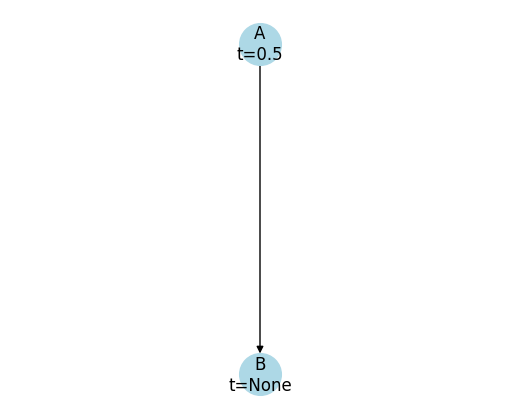

In [4]:
import string

diff_map_edges = [
    ("A", "B"),
]

diff_times = [0.5, None]

diff_T = nx.DiGraph()

for i, t in enumerate(diff_times):
    diff_T.add_node(string.ascii_uppercase[i], diff_time = t)

for s, e in diff_map_edges:
    diff_T.add_edge(s, e)

plot_differentiation_tree(diff_T)

### simulate tree

In [12]:
from plotters import plot_simulated_lineage_tree
from simulator import simulate_multitype_bd_with_diff, save_tree, filter_extant_lineages

save_dir = "../data/simulation/test_diff_piecewise"

lam = {
    "A": 5.0,
    "B": 2.0,
}

mu = {
    "A": 0.3,
    "B": 0.2,
}

import pandas as pd

types = list(diff_T.nodes)

Qs = pd.DataFrame(0.0, index=types, columns=types)

# A -> B
Qs.loc["A", "B"] = 1.0


G, root = simulate_multitype_bd_with_diff(
    lam=lam,
    mu=mu,
    diff_T=diff_T,
    Qs=Qs,
    time_length=1.0,
    root_type="A",
    seed=4
)

for u, v, data in G.edges(data=True):
    print((u, v), data)

save_tree(G, root, f"{save_dir}/T.json")
plot_simulated_lineage_tree(G, root)

plt.savefig(f"{save_dir}/T.png")
plt.close()

G_extant = filter_extant_lineages(G, root)

save_tree(G_extant, root, f"{save_dir}/T_extant.json")

plot_simulated_lineage_tree(G_extant, root)

plt.savefig(f"{save_dir}/T_extant.png")
plt.close()


(0, 1) {'start_time': 0.0, 'end_time': 0.05080196914702305, 'length': 0.05080196914702305}
(1, 2) {'start_time': 0.05080196914702305, 'end_time': 0.06668742542484705, 'length': 0.015885456277824006}
(1, 3) {'start_time': 0.05080196914702305, 'end_time': 0.24294008378402152, 'length': 0.19213811463699848}
(2, 4) {'start_time': 0.06668742542484705, 'end_time': 0.43660822690361484, 'length': 0.36992080147876777}
(2, 5) {'start_time': 0.06668742542484705, 'end_time': 0.22395081705547248, 'length': 0.15726339163062542}
(3, 10) {'start_time': 0.24294008378402152, 'end_time': 0.32545054464449125, 'length': 0.08251046086046973}
(3, 11) {'start_time': 0.24294008378402152, 'end_time': 0.5, 'length': 0.25705991621597846}
(4, 18) {'start_time': 0.43660822690361484, 'end_time': 0.5, 'length': 0.06339177309638516}
(4, 19) {'start_time': 0.43660822690361484, 'end_time': 0.5, 'length': 0.06339177309638516}
(5, 6) {'start_time': 0.22395081705547248, 'end_time': 0.23578744157909423, 'length': 0.01183662

### check likelihood 

In [13]:
from simulator import load_tree

In [14]:
T, root = load_tree(f"{save_dir}/T_extant.json")

In [15]:
for u, v, data in T.edges(data=True):
    print(f"{u} -> {v} : {data}")

0 -> 1 : {'start_time': 0.0, 'end_time': 0.05080196914702305, 'length': 0.05080196914702305}
1 -> 2 : {'start_time': 0.05080196914702305, 'end_time': 0.06668742542484705, 'length': 0.015885456277824006}
1 -> 3 : {'start_time': 0.05080196914702305, 'end_time': 0.24294008378402152, 'length': 0.19213811463699848}
2 -> 4 : {'start_time': 0.06668742542484705, 'end_time': 0.43660822690361484, 'length': 0.36992080147876777}
2 -> 5 : {'start_time': 0.06668742542484705, 'end_time': 0.22395081705547248, 'length': 0.15726339163062542}
3 -> 10 : {'start_time': 0.24294008378402152, 'end_time': 0.32545054464449125, 'length': 0.08251046086046973}
3 -> 25 : {'start_time': 0.24294008378402152, 'end_time': 0.8305607896076935, 'length': 0.587620705823672}
4 -> 30 : {'start_time': 0.43660822690361484, 'end_time': 0.58280374622013, 'length': 0.14619551931651514}
4 -> 31 : {'start_time': 0.43660822690361484, 'end_time': 1.0, 'length': 0.5633917730963851}
5 -> 6 : {'start_time': 0.22395081705547248, 'end_tim

In [16]:
cell_lineage_T = nx.DiGraph()

for u, v, data in T.edges(data=True):
    cell_lineage_T.add_edge(u, v, weight=data['length'])

for n in T.nodes(data=True):
    if n[1]['event'] == 'sample':
        cell_lineage_T.nodes[n[0]]['type'] = n[1]['type']

In [17]:
from plotters import draw_ultrametric_tree

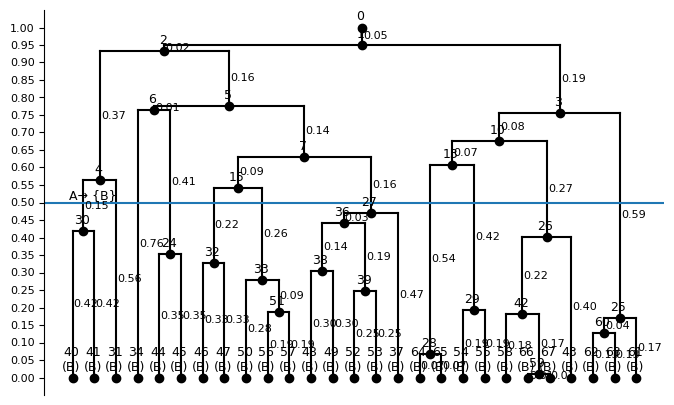

In [18]:
draw_ultrametric_tree(cell_lineage_T, root=root, diff_T=diff_T)

In [19]:
def add_node_times(cell_lineage_T, root=0):
    distances = nx.single_source_dijkstra_path_length(cell_lineage_T, root, weight='weight')
    for node, dist in distances.items():
        cell_lineage_T.nodes[node]['T'] = 1 - dist
    
    return cell_lineage_T

cell_lineage_T = add_node_times(cell_lineage_T)

In [21]:
from likelihood import calculate_likelihood_of_tree

In [35]:
birth_rates = {
    "A": 5.0,
    "B": 2.0,
}
death_rates = {
    "A": 0.3,
    "B": 0.2,
}


transition_probabilities = pd.DataFrame(0.0, index=types, columns=types)

# A -> B
transition_probabilities.loc["A", "B"] = 1.0


calculate_likelihood_of_tree(
    birth_rates=birth_rates,
    death_rates=death_rates,
    sampling_rate=1.0,
    transition_probabilities=transition_probabilities,
    cell_lineage_T=cell_lineage_T,
    diff_T=diff_T
)

np.float64(0.003985656272609176)

In [36]:
import numpy as np

def likelihood_grid(
    birth_grid_A,
    birth_grid_B,
    death_grid_A,
    death_grid_B,
    cell_lineage_T,
    diff_T,
    transition_probabilities
):
    """
    Compute likelihood over 4D grid:
    (λ_A, λ_B, μ_A, μ_B)
    """

    L = np.zeros((
        len(death_grid_A),
        len(death_grid_B),
        len(birth_grid_A),
        len(birth_grid_B)
    ))

    for iA, lam_A in enumerate(birth_grid_A):
        for iB, lam_B in enumerate(birth_grid_B):
            for jA, mu_A in enumerate(death_grid_A):
                for jB, mu_B in enumerate(death_grid_B):

                    birth_rates = {
                        "A": lam_A,
                        "B": lam_B,
                    }

                    death_rates = {
                        "A": mu_A,
                        "B": mu_B,
                    }

                    L[jA, jB, iA, iB] = calculate_likelihood_of_tree(
                        birth_rates=birth_rates,
                        death_rates=death_rates,
                        sampling_rate=1.0,
                        transition_probabilities=transition_probabilities,
                        cell_lineage_T=cell_lineage_T,
                        diff_T=diff_T
                    )

    return L


In [37]:
import matplotlib.pyplot as plt
import numpy as np

def plot_likelihood_slice(
    birth_grid_A,
    death_grid_A,
    L,
    fixed_mu_B_idx,
    fixed_lam_B_idx
):
    """
    Plot slice L[μ_A, μ_B_fixed, λ_A, λ_B_fixed]
    """

    L_slice = L[:, fixed_mu_B_idx, :, fixed_lam_B_idx]

    plt.figure(figsize=(6, 5))

    plt.imshow(
        L_slice,
        origin="lower",
        extent=[
            birth_grid_A.min(), birth_grid_A.max(),
            death_grid_A.min(), death_grid_A.max(),
        ],
        aspect="auto"
    )

    plt.xlabel("λ_A")
    plt.ylabel("μ_A")
    plt.colorbar(label="Likelihood")
    plt.tight_layout()
    plt.show()


In [40]:
birth_grid_A = np.linspace(0.0, 8.0, 25)
death_grid_A = np.linspace(0.0, 8.0, 25)

birth_grid_B = np.linspace(0.0, 8.0, 25)
death_grid_B = np.linspace(0.0, 8.0, 25)


In [41]:
L = likelihood_grid(
    birth_grid_A,
    birth_grid_B,
    death_grid_A,
    death_grid_B,
    cell_lineage_T=cell_lineage_T,
    diff_T=diff_T,
    transition_probabilities=transition_probabilities
)


In [42]:
fixed_lam_B_idx = 10
fixed_mu_B_idx = 5

In [43]:
L_slice = L[:, fixed_mu_B_idx, :, fixed_lam_B_idx]

In [44]:
import matplotlib.pyplot as plt
import numpy as np

def plot_likelihood_slice(
    birth_grid_A,
    death_grid_A,
    L,
    fixed_mu_B_idx,
    fixed_lam_B_idx
):
    """
    Plot slice L[μ_A, μ_B_fixed, λ_A, λ_B_fixed]
    """

    L_slice = L[:, fixed_mu_B_idx, :, fixed_lam_B_idx]

    plt.figure(figsize=(6, 5))

    plt.imshow(
        L_slice,
        origin="lower",
        extent=[
            birth_grid_A.min(), birth_grid_A.max(),
            death_grid_A.min(), death_grid_A.max(),
        ],
        aspect="auto"
    )

    plt.xlabel("λ_A")
    plt.ylabel("μ_A")
    plt.colorbar(label="Likelihood")
    plt.tight_layout()
    plt.show()


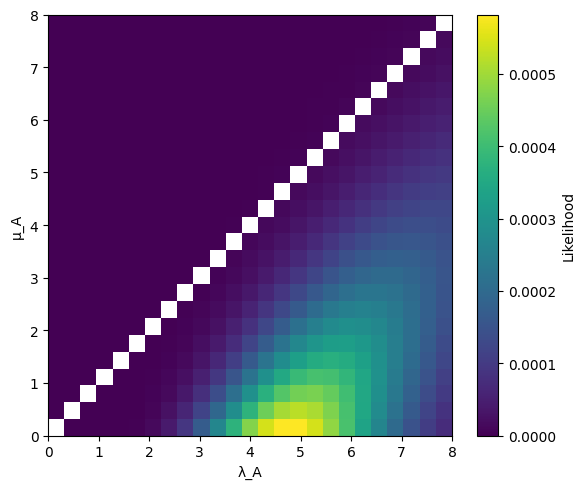

In [48]:
plot_likelihood_slice(
    birth_grid_A,
    death_grid_A,
    L,
    fixed_mu_B_idx,
    fixed_lam_B_idx
)


In [49]:
import numpy as np
import matplotlib.pyplot as plt

def plot_likelihood_surface(
    birth_grid,
    death_grid,
    L2D,
    true_lambda=None,
    true_mu=None,
    title=None,
    log_scale=False
):
    """
    Plot a 2D likelihood surface.

    Parameters
    ----------
    birth_grid : array-like
        Grid for λ (x-axis)

    death_grid : array-like
        Grid for μ (y-axis)

    L2D : 2D numpy array
        Likelihood slice with shape:
        (len(death_grid), len(birth_grid))

    true_lambda : float, optional
        True λ value to mark on plot

    true_mu : float, optional
        True μ value to mark on plot

    title : str, optional
        Plot title

    log_scale : bool
        If True, plot log-likelihood
    """

    if log_scale:
        # Avoid log(0)
        L_plot = np.log(L2D + 1e-300)
        color_label = "Log-Likelihood"
    else:
        L_plot = L2D
        color_label = "Likelihood"

    plt.figure(figsize=(6, 5))

    im = plt.imshow(
        L_plot,
        origin="lower",
        extent=[
            birth_grid.min(), birth_grid.max(),
            death_grid.min(), death_grid.max(),
        ],
        aspect="auto"
    )

    plt.xlabel("Birth rate λ")
    plt.ylabel("Death rate μ")

    if title is not None:
        plt.title(title)

    plt.colorbar(im, label=color_label)

    # Mark true parameter if provided
    if true_lambda is not None and true_mu is not None:
        plt.scatter(true_lambda, true_mu, marker="x", s=100)
    
    plt.tight_layout()
    plt.show()


In [50]:
idx_lam_A = np.argmin(np.abs(birth_grid_A - 5.0))
idx_mu_A  = np.argmin(np.abs(death_grid_A - 0.3))

idx_lam_B = np.argmin(np.abs(birth_grid_B - 2.0))
idx_mu_B  = np.argmin(np.abs(death_grid_B - 0.2))


In [51]:
L_A = L[:, idx_mu_B, :, idx_lam_B]
L_B = L[idx_mu_A, :, idx_lam_A, :]

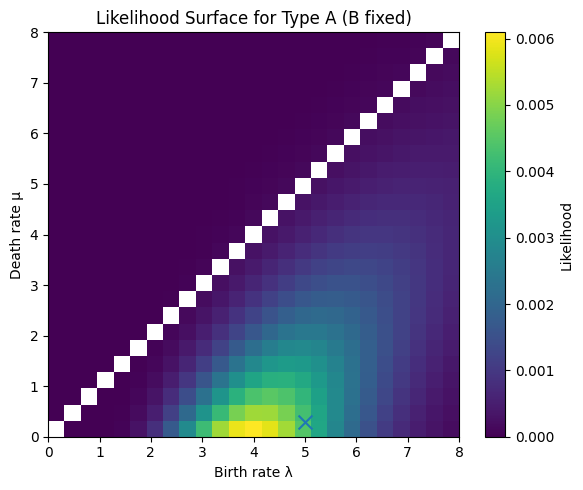

In [53]:
plot_likelihood_surface(
    birth_grid_A,
    death_grid_A,
    L_A,
    true_lambda=5.0,
    true_mu=0.3,
    title="Likelihood Surface for Type A (B fixed)",
)


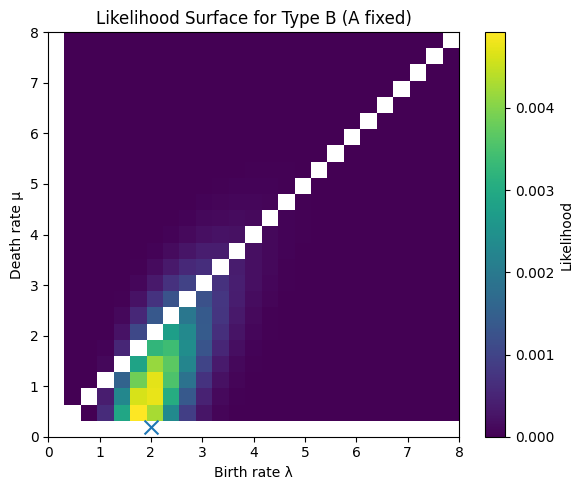

In [54]:
plot_likelihood_surface(
    birth_grid_B,
    death_grid_B,
    L_B,
    true_lambda=2.0,
    true_mu=0.2,
    title="Likelihood Surface for Type B (A fixed)",
)
